# 08 Robustness of the frozen mining pipeline across scenarios (SIMULATED)

The pipeline frozen on 2024-01-01..2024-10-31 (medium) is run **unchanged** on the low, medium and high SIMULATED scenarios for 2025-01-01..2025-08-31 (headway 3/4/6 min, freight 0.02/0.04/0.06, same timetable). No ground truth is read. Same trains and days, different congestion, so the question is whether the conclusions move with the world's congestion. The headway is 3 min in low, 4 in medium and 6 in high (more headway means more queueing); freight 0.02 / 0.04 / 0.06.

In [1]:
import os, sys, warnings
os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None
sys.path.insert(0, "."); warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.analysis import mining_pipeline as mp, robustness as rb
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
COL = {"low": "#6a9f58", "medium": "#1f6f9f", "high": "#b5483a"}; S = "  [SIMULATED]"
FIG = Path("reports/figures")
W = ("2025-01-01", "2025-08-31"); R = {s: mp.load_saved(*W, scenario=s) for s in COL}
pd.set_option("display.width", 200)
print({s: (len(R[s]["cascades"]), len(R[s]["primary_events"]), len(R[s]["passage_links"])) for s in R}, "(cascades, primary events, section links)")

{'low': (8946, 4926, 77532), 'medium': (9640, 6728, 108651), 'high': (12033, 14696, 165563)} (cascades, primary events, section links)


## Critical sections: is the ranking stable?

         measure           pair  spearman  top_overlap
     origin_freq  low vs medium     0.908            7
     origin_freq    low vs high     0.781            6
     origin_freq medium vs high     0.848            7
  size_triggered  low vs medium     0.887            9
  size_triggered    low vs high     0.808            6
  size_triggered medium vs high     0.839            6
 primary_minutes  low vs medium     0.939            8
 primary_minutes    low vs high     0.815            5
 primary_minutes medium vs high     0.864            6
pagerank_station  low vs medium     0.903            8
pagerank_station    low vs high     0.805            6
pagerank_station medium vs high     0.775            6
edge_betweenness  low vs medium     1.000           10
edge_betweenness    low vs high     1.000           10
edge_betweenness medium vs high     1.000           10
low ['ETW-EKL', 'CNB-CNBI', 'ARW-JEP', 'MNR-SKB', 'PHD-KNS', 'PATA-PHD', 'FZD-MNR', 'JJK-AAP']
medium ['ETW-EKL', 'CNB-C

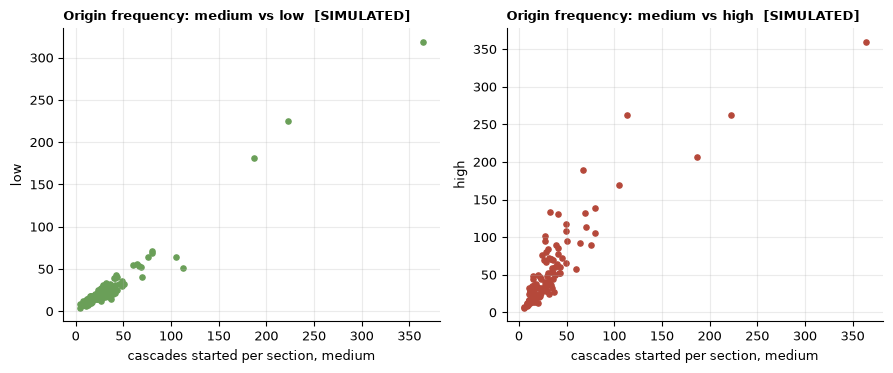

In [2]:
rs = rb.ranking_stability({s: R[s]["critical_sections"] for s in R}); print(rs.round(3).to_string(index=False))
tops = {s: R[s]["critical_sections"].sort_values("origin_freq", ascending=False).head(8).section.tolist() for s in R}
for s, t in tops.items(): print(s, t)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
c = {s: R[s]["critical_sections"].set_index("sec").origin_freq for s in R}
for ax, o in zip(axes, ("low", "high")):
    ax.scatter(c["medium"], c[o], s=14, color=COL[o]); ax.set_xlabel("cascades started per section, medium"); ax.set_ylabel(f"{o}")
    ax.set_title(f"Origin frequency: medium vs {o}" + S, loc="left", fontweight="bold", fontsize=9)
plt.tight_layout(); fig.savefig(FIG / "robustness_01_origin_frequency.png", dpi=130, bbox_inches="tight"); plt.show()

## Cascade size distribution

                  low    medium       high
n_cascades   8946.000  9640.000  12033.000
mean            2.178     2.387      2.396
median          1.000     1.000      1.000
p90             5.000     5.000      5.000
p99            12.000    14.000     14.000
max            35.000    43.000     31.000
mean_depth      0.855     1.006      1.034
mean_extent     1.844     1.969      1.987
share>=1        1.000     1.000      1.000
share>=2        0.407     0.434      0.434
share>=3        0.228     0.258      0.265
share>=5        0.104     0.125      0.129
share>=10       0.020     0.029      0.032
share>=20       0.002     0.003      0.002


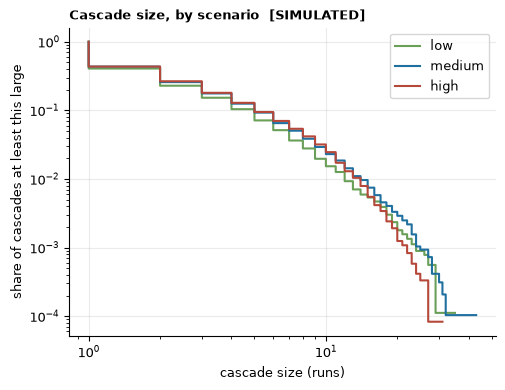

In [3]:
sd = pd.DataFrame({s: rb.size_distribution(R[s]["cascades"]) for s in R}); print(sd.round(3).to_string())
fig, ax = plt.subplots(figsize=(5.5, 4))
for s in R:
    z = np.sort(R[s]["cascades"].size_runs.to_numpy()); ax.step(z, 1 - np.arange(len(z)) / len(z), color=COL[s], label=s)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("cascade size (runs)"); ax.set_ylabel("share of cascades at least this large"); ax.legend()
ax.set_title("Cascade size, by scenario" + S, loc="left", fontweight="bold", fontsize=9); fig.savefig(FIG / "robustness_02_cascade_size.png", dpi=130, bbox_inches="tight"); plt.show()

## Contagion coefficients

  measure           pair  spearman   n  median_low  median_medium  median_high
      rho  low vs medium     0.940 214       0.459          0.485        0.475
      rho    low vs high     0.879 214       0.459          0.485        0.475
      rho medium vs high     0.909 214       0.459          0.485        0.475
    A_all  low vs medium     0.911 214       0.012          0.012        0.012
    A_all    low vs high     0.880 214       0.012          0.012        0.012
    A_all medium vs high     0.907 214       0.012          0.012        0.012
A_primary  low vs medium     0.568  34       0.333          0.342        0.276
A_primary    low vs high     0.506  34       0.333          0.342        0.276
A_primary medium vs high     0.586  77       0.333          0.342        0.276
     beta  low vs medium     0.666 214       0.003          0.003        0.005
     beta    low vs high     0.507 214       0.003          0.003        0.005
     beta medium vs high     0.645 214       0.003  

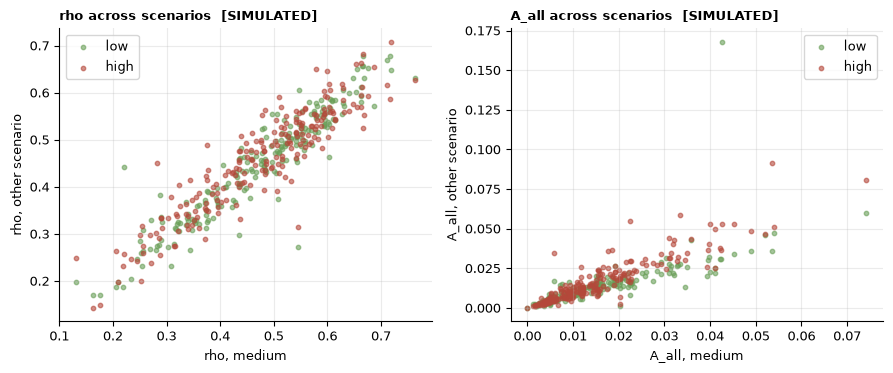

In [4]:
cs = rb.contagion_stability({s: R[s]["contagion"] for s in R}); print(cs.round(3).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, col in zip(axes, ("rho", "A_all")):
    x = R["medium"]["contagion"].set_index(["sec", "dir"])[col]
    for o in ("low", "high"):
        y = R[o]["contagion"].set_index(["sec", "dir"])[col]; xx, yy = x.align(y, join="inner"); ax.scatter(xx, yy, s=10, color=COL[o], alpha=0.6, label=o)
    ax.set_xlabel(f"{col}, medium"); ax.set_ylabel(f"{col}, other scenario"); ax.legend(); ax.set_title(col + " across scenarios" + S, loc="left", fontweight="bold", fontsize=9)
plt.tight_layout(); fig.savefig(FIG / "robustness_03_contagion.png", dpi=130, bbox_inches="tight"); plt.show()